# 01 - Data Loading, Inspection and Cleaning
**Project:** Customer Churn Prediction (IBM Telco dataset)

**Goal of this notebook:** load the raw data, understand its structure and quality, fix the problems we find,
and save a clean file for the EDA and modeling notebooks.

**Steps**
1. Load the data
2. Inspect shape, types and the target variable
3. Check data quality (missing values, duplicates, odd categories)
4. Clean the data
5. Validate the cleaned data and save it

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

RAW = "../data/raw/Telco-Customer-Churn.csv"
CLEAN = "../data/processed/churn_clean.csv"

## 1. Load the data

In [2]:
df_raw = pd.read_csv(RAW)
df = df_raw.copy()          # always keep the raw copy untouched
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Inspect the data

In [3]:
print("Rows, columns:", df.shape)
df.info()

Rows, columns: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

In [4]:
df.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [5]:
# Summary of categorical columns: how many unique values and what are they?
# (TotalCharges is skipped here because it is text by mistake - see section 3)
cat_cols = df.select_dtypes(exclude="number").columns.drop(["customerID", "TotalCharges"])
for c in cat_cols:
    print(f"{c:18s} {df[c].nunique()} -> {sorted(df[c].unique())}")

gender             2 -> ['Female', 'Male']
Partner            2 -> ['No', 'Yes']
Dependents         2 -> ['No', 'Yes']
PhoneService       2 -> ['No', 'Yes']
MultipleLines      3 -> ['No', 'No phone service', 'Yes']
InternetService    3 -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity     3 -> ['No', 'No internet service', 'Yes']
OnlineBackup       3 -> ['No', 'No internet service', 'Yes']
DeviceProtection   3 -> ['No', 'No internet service', 'Yes']
TechSupport        3 -> ['No', 'No internet service', 'Yes']
StreamingTV        3 -> ['No', 'No internet service', 'Yes']
StreamingMovies    3 -> ['No', 'No internet service', 'Yes']
Contract           3 -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   2 -> ['No', 'Yes']
PaymentMethod      4 -> ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              2 -> ['No', 'Yes']


### Target variable: Churn

       customers  percent
Churn                    
No          5174     73.5
Yes         1869     26.5


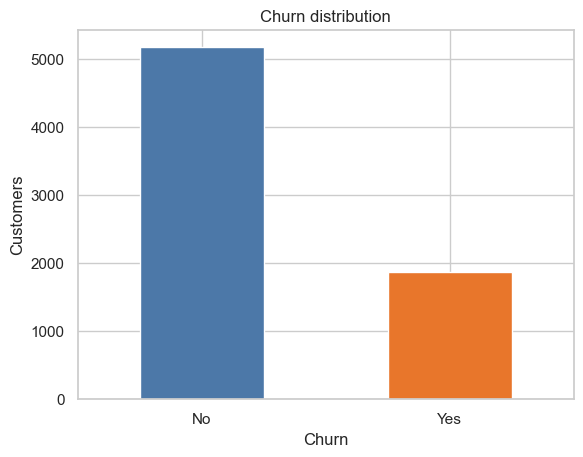

In [6]:
counts = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({"customers": counts, "percent": pct}))

ax = counts.plot(kind="bar", color=["#4C78A8", "#E8762B"], rot=0)
ax.set_title("Churn distribution")
ax.set_ylabel("Customers")
plt.show()

**Observation:** about 26.5% of customers churned, so the classes are **imbalanced**.
A model that always predicts "No" would already score about 73.5% accuracy, which is why we will judge
models with recall, precision, F1 and ROC-AUC instead of accuracy alone.

## 3. Data quality checks

In [7]:
print("Missing values (NaN) per column:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "none")
print()
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

Missing values (NaN) per column:
none

Duplicate rows: 0
Duplicate customerIDs: 0


`TotalCharges` is stored as text (object) even though it should be a number. Something in that column is not numeric.
Let's find out what.

In [8]:
tc_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
bad = df[tc_num.isna()]
print("Rows where TotalCharges is not numeric:", len(bad))
print("Distinct raw values there:", bad["TotalCharges"].unique())
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows where TotalCharges is not numeric: 11
Distinct raw values there: [' ']


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Finding:** all 11 problem rows have a blank string (a space) in `TotalCharges` and `tenure = 0`.
These are brand-new customers who have not been billed yet, so their true total is **0**, not an unknown value.
None of them churned. We will set `TotalCharges = 0` for them rather than dropping the rows.

In [9]:
# Other things worth checking
print("tenure == 0 rows:", (df["tenure"] == 0).sum())
print("SeniorCitizen values:", sorted(df["SeniorCitizen"].unique()))

# Consistency: 'No internet service' should appear only where InternetService == 'No'
internet_addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies"]
for c in internet_addons:
    ok = (df[c].eq("No internet service") == df["InternetService"].eq("No")).all()
    print(f"{c:18s} consistent with InternetService=='No': {ok}")
print("MultipleLines 'No phone service' consistent with PhoneService=='No':",
      (df["MultipleLines"].eq("No phone service") == df["PhoneService"].eq("No")).all())

tenure == 0 rows: 11
SeniorCitizen values: [np.int64(0), np.int64(1)]
OnlineSecurity     consistent with InternetService=='No': True
OnlineBackup       consistent with InternetService=='No': True
DeviceProtection   consistent with InternetService=='No': True
TechSupport        consistent with InternetService=='No': True
StreamingTV        consistent with InternetService=='No': True
StreamingMovies    consistent with InternetService=='No': True
MultipleLines 'No phone service' consistent with PhoneService=='No': True


**Finding:** "No internet service" and "No phone service" are not errors. They always line up with
`InternetService = No` and `PhoneService = No`. We will recode them to plain "No" in the cleaned version because the
information is already held in `InternetService` / `PhoneService`; this keeps the binary columns clean for modeling.

## 4. Clean the data

In [10]:
# 4.1 TotalCharges: text -> number, blanks (new customers) -> 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip().replace("", np.nan), errors="coerce")
df.loc[df["tenure"] == 0, "TotalCharges"] = df.loc[df["tenure"] == 0, "TotalCharges"].fillna(0)
print("TotalCharges missing after fix:", df["TotalCharges"].isna().sum())

# 4.2 Recode 'No internet service' / 'No phone service' to 'No'
for c in internet_addons + ["MultipleLines"]:
    df[c] = df[c].replace({"No internet service": "No", "No phone service": "No"})

# 4.3 SeniorCitizen: 0/1 -> No/Yes so it matches the other binary columns
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# 4.4 Target: add a 0/1 version for modeling (keep the text label too)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

# 4.5 Strip stray whitespace in text columns
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].str.strip()

df.dtypes

TotalCharges missing after fix: 0


customerID           object
gender               object
SeniorCitizen        object
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
ChurnFlag             int64
dtype: object

## 5. Validate and save

In [11]:
# Each check must pass, otherwise the cell raises an error
assert df.shape[0] == df_raw.shape[0], "row count changed"
assert df["customerID"].is_unique
assert df["TotalCharges"].notna().all()
assert df["TotalCharges"].dtype == "float64"
assert set(df["Churn"].unique()) == {"Yes", "No"}
assert df["ChurnFlag"].sum() == (df_raw["Churn"] == "Yes").sum()
assert (df["TotalCharges"] >= 0).all()

# TotalCharges should be roughly tenure x MonthlyCharges for most customers
ratio = (df["TotalCharges"] / (df["tenure"] * df["MonthlyCharges"]).replace(0, np.nan)).dropna()
print("TotalCharges / (tenure x MonthlyCharges): median = %.2f, 5th-95th pct = %.2f to %.2f"
      % (ratio.median(), ratio.quantile(.05), ratio.quantile(.95)))
print("All checks passed.")

TotalCharges / (tenure x MonthlyCharges): median = 1.00, 5th-95th pct = 0.92 to 1.07
All checks passed.


In [12]:
df.to_csv(CLEAN, index=False)
print("Saved:", CLEAN, df.shape)
df.head()

Saved: ../data/processed/churn_clean.csv (7043, 22)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


## Summary of this notebook
| Issue found | Fix |
|---|---|
| `TotalCharges` stored as text; 11 blank values | Converted to numeric; blanks are new customers (tenure 0) so set to 0 |
| "No internet service" / "No phone service" categories | Recoded to "No" (info already in `InternetService` / `PhoneService`) |
| `SeniorCitizen` coded 0/1 while other flags are Yes/No | Mapped to No/Yes |
| Target stored as text | Added `ChurnFlag` (0/1) |
